<a href="https://colab.research.google.com/github/mahavalnedatin04/analisis-segmentasi-PCA-K-Means/blob/main/analisis_segmentasi_pca_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# ANALISIS PCA - K-MEANS KEPUASAN PERPUSTAKAAN SAINTEK
# ============================================================

!pip -q install factor_analyzer openpyxl statsmodels

import os
import json
import zipfile
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display

from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.stats import f_oneway, levene, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.float_format", lambda x: f"{x:.6f}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# ------------------------------------------------------------
# 1. MEMBACA DATA GOOGLE SHEETS
# ------------------------------------------------------------

SHEET_ID = "1EY4kHjdgJMfEEwgol5N7JuyB1zkX4lyP"
URL_XLSX = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=xlsx"

# Tautan harus dapat diakses publik atau dibagikan sebagai viewer.
data = pd.read_excel(URL_XLSX, sheet_name=0)
print("Ukuran data awal:", data.shape)

# Dua puluh dua item survei berada pada kolom ke-9 sampai ke-30.
kolom_survei = list(data.columns[8:30])
assert len(kolom_survei) == 22, "Jumlah item survei bukan 22"

Ukuran data awal: (1646, 37)


Jumlah sel kosong atau tidak valid: 0
Jumlah baris yang terpengaruh: 0
Jumlah nilai di luar rentang 1 sampai 5: 0
Jumlah data setelah pemeriksaan: 1646


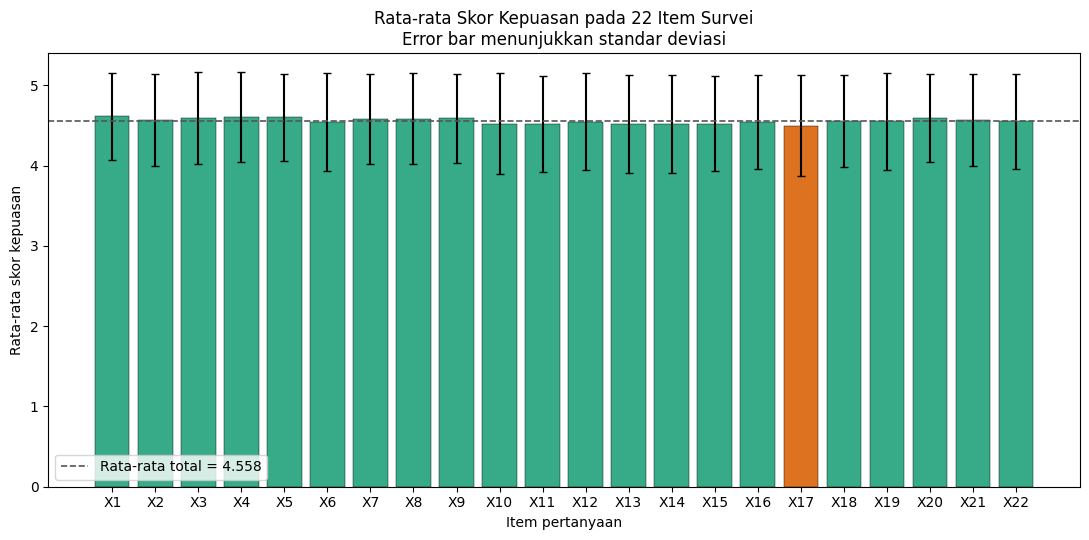

Grafik berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_1_Rata_Rata_Item.png


In [ ]:
# ------------------------------------------------------------
# 2. KONVERSI SKALA LIKERT DAN PEMERIKSAAN DATA
# ------------------------------------------------------------

mapping = {
    "Sangat Memuaskan": 5,
    "Memuaskan": 4,
    "Cukup Memuaskan": 3,
    "Tidak Memuaskan": 2,
    "Sangat Tidak Memuaskan": 1,
}

data_survei = data[kolom_survei].copy()

for kategori, skor in mapping.items():
    data_survei = data_survei.mask(
        data_survei.eq(kategori),
        skor
    )

data_survei = data_survei.apply(
    pd.to_numeric,
    errors="coerce"
)

missing_cells = int(data_survei.isna().sum().sum())
missing_rows = int(data_survei.isna().any(axis=1).sum())
invalid_range = int(((data_survei < 1) | (data_survei > 5)).sum().sum())
print("Jumlah sel kosong atau tidak valid:", missing_cells)
print("Jumlah baris yang terpengaruh:", missing_rows)
print("Jumlah nilai di luar rentang 1 sampai 5:", invalid_range)
assert invalid_range == 0, "Terdapat nilai di luar rentang skala Likert 1 sampai 5"

# Respons kosong atau tidak valid dihapus secara listwise.
data_survei = data_survei.dropna(axis=0, how="any").copy()
print("Jumlah data setelah pemeriksaan:", len(data_survei))

# ============================================================
# GRAFIK SETELAH PRA-PEMROSESAN DATA
# RATA-RATA SKOR KEPUASAN PADA 22 ITEM
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

# Folder penyimpanan grafik
GRAFIK_DIR = "grafik_7_gambar"
os.makedirs(GRAFIK_DIR, exist_ok=True)

# Nama item survei
item_names = [f"X{i}" for i in range(1, 23)]

# Menghitung rata-rata dan standar deviasi setiap item
item_mean = data_survei.mean(axis=0)
item_std = data_survei.std(axis=0, ddof=1)

# Menentukan warna batang
# Batang oranye menunjukkan nilai rata-rata terendah
# Batang hijau menunjukkan item lainnya
warna_batang = [
    "#d95f02" if nilai == item_mean.min() else "#1b9e77"
    for nilai in item_mean
]

# Membuat grafik
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(
    item_names,
    item_mean.values,
    yerr=item_std.values,
    capsize=3,
    color=warna_batang,
    alpha=0.88,
    edgecolor="black",
    linewidth=0.35,
)

# Garis rata-rata seluruh skor
rata_rata_total = data_survei.to_numpy().mean()

ax.axhline(
    rata_rata_total,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Rata-rata total = {rata_rata_total:.3f}",
)

# Pengaturan grafik
ax.set_ylim(0, 5.4)
ax.set_xlabel("Item pertanyaan")
ax.set_ylabel("Rata-rata skor kepuasan")
ax.set_title(
    "Rata-rata Skor Kepuasan pada 22 Item Survei\n"
    "Error bar menunjukkan standar deviasi"
)
ax.legend(loc="lower left")

plt.tight_layout()

# Menyimpan grafik
nama_file = f"{GRAFIK_DIR}/Gambar_1_Rata_Rata_Item.png"
plt.savefig(nama_file, dpi=300, bbox_inches="tight")

# Menampilkan grafik langsung di Google Colab
plt.show()

# Menutup objek grafik
plt.close()

print(f"Grafik berhasil dibuat dan disimpan di: {nama_file}")


In [ ]:
# ------------------------------------------------------------
# 3. UJI KMO, BARTLETT, DAN CRONBACH ALPHA (2.3.2)
# ------------------------------------------------------------

bartlett_chi2, bartlett_p_value = calculate_bartlett_sphericity(data_survei)
kmo_all, kmo_model = calculate_kmo(data_survei)

item_variances = data_survei.var(axis=0, ddof=1)
total_variance = data_survei.sum(axis=1).var(ddof=1)
cronbach_alpha = (22 / 21) * (1 - item_variances.sum() / total_variance)

print("KMO:", kmo_model)
print("Bartlett Chi-Square:", bartlett_chi2)
print("Bartlett p-value:", bartlett_p_value)
print("Cronbach alpha:", cronbach_alpha)

KMO: 0.9800062462325756
Bartlett Chi-Square: 41798.31027404061
Bartlett p-value: 0.0
Cronbach alpha: 0.9799526486338073


/usr/local/lib/python3.13/dist-packages/factor_analyzer/utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


Jumlah komponen: 4
Eigenvalue: [15.53291656  1.14063283  0.69273712  0.49714915]
Varians komponen (%): [70.56127178  5.18154481  3.14689208  2.258396  ]
Varians kumulatif (%): 81.14810466162317

Factor loading:


,PC1,PC2,PC3,PC4
X1,0.794737,0.293980,0.033294,0.388335
X2,0.810629,0.332902,-0.049232,0.249477
X3,0.805559,0.356585,0.019799,0.189185
X4,0.828450,0.308210,0.000017,-0.062247
X5,0.848255,0.278398,-0.020568,-0.038436
X6,0.823364,0.257654,0.007026,-0.142056
X7,0.859476,0.206817,-0.086302,-0.221819
X8,0.858109,0.213215,-0.015023,-0.276216
X9,0.874211,0.178390,-0.001257,-0.219112
X10,0.812032,-0.141340,-0.308674,-0.063090


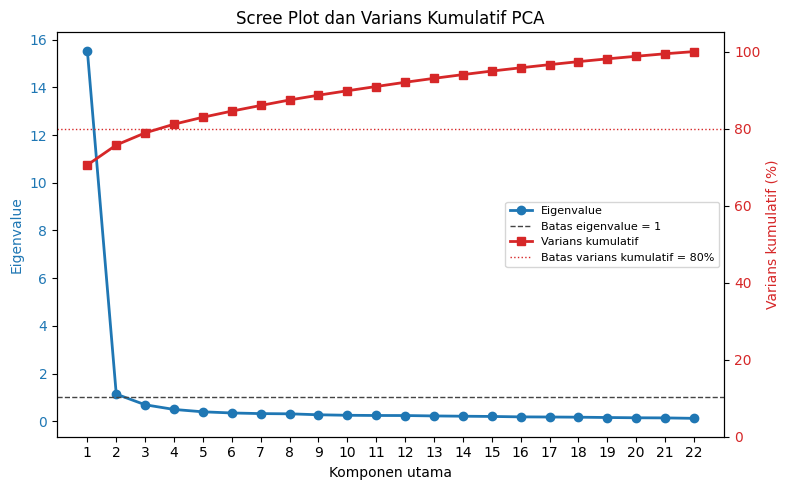

Scree Plot berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_2_Scree_Plot_PCA.png


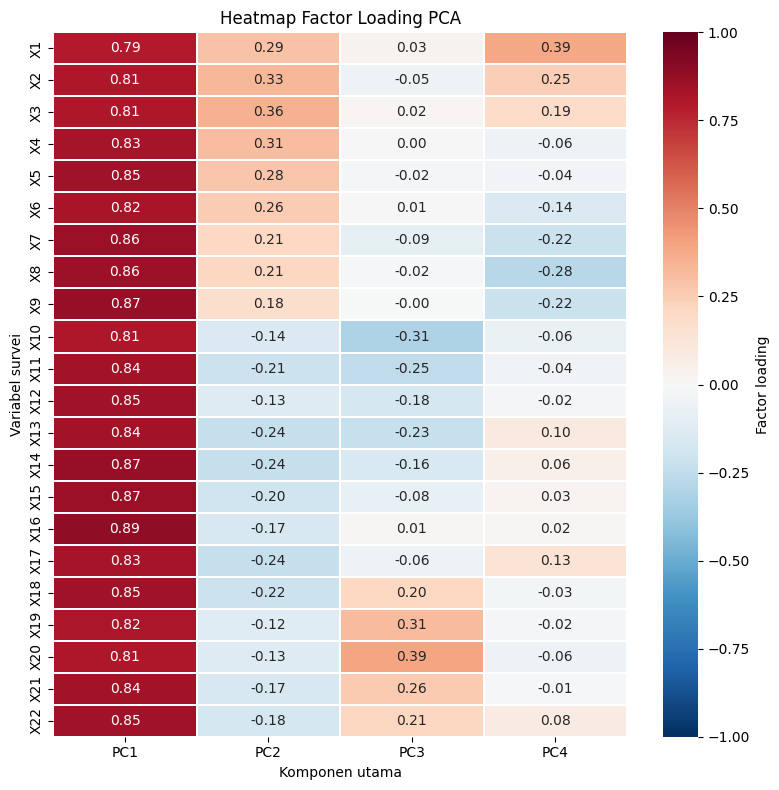

Heatmap factor loading berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_3_Heatmap_Loading_PCA.png


In [ ]:
# ------------------------------------------------------------
# 4. STANDARDISASI DAN PCA (2.3.3)
# ------------------------------------------------------------

scaler = StandardScaler()
X = scaler.fit_transform(data_survei)

# PCA awal untuk menentukan jumlah komponen sampai varians kumulatif >= 80%.
pca_full = PCA().fit(X)
variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = variance_ratio.cumsum()
jumlah_komponen = int(np.where(cumulative_variance >= 0.80)[0][0] + 1)

pca = PCA(n_components=jumlah_komponen).fit(X)
hasil_pca = pca.transform(X)
kolom_pc = [f"PC{i+1}" for i in range(jumlah_komponen)]

# Factor loading yang benar = eigenvector x akar eigenvalue.
loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=[f"X{i}" for i in range(1, 23)],
    columns=kolom_pc,
)

print("Jumlah komponen:", jumlah_komponen)
print("Eigenvalue:", pca.explained_variance_)
print("Varians komponen (%):", pca.explained_variance_ratio_ * 100)
print("Varians kumulatif (%):", pca.explained_variance_ratio_.sum() * 100)
print("\nFactor loading:")
display(loadings)

# ------------------------------------------------------------
# GRAFIK 2. SCREE PLOT DAN VARIANS KUMULATIF PCA
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np

# Mengambil seluruh eigenvalue dari PCA lengkap
eigenvalue_lengkap = pca_full.explained_variance_

# Varians setiap komponen dalam persen
varians_lengkap = pca_full.explained_variance_ratio_ * 100

# Varians kumulatif seluruh komponen
varians_kumulatif_lengkap = np.cumsum(varians_lengkap)

# Nomor komponen dari 1 sampai 22
komponen = np.arange(
    1,
    len(eigenvalue_lengkap) + 1
)

fig, ax1 = plt.subplots(figsize=(8, 5))

# ------------------------------------------------------------
# GARIS BIRU: EIGENVALUE
# ------------------------------------------------------------

ax1.plot(
    komponen,
    eigenvalue_lengkap,
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Eigenvalue"
)

# Garis batas eigenvalue = 1
ax1.axhline(
    1,
    color="#444444",
    linestyle="--",
    linewidth=1,
    label="Batas eigenvalue = 1"
)

ax1.set_xlabel("Komponen utama")
ax1.set_ylabel(
    "Eigenvalue",
    color="#1f77b4"
)

ax1.tick_params(
    axis="y",
    labelcolor="#1f77b4"
)

ax1.set_xticks(komponen)

# ------------------------------------------------------------
# GARIS MERAH: VARIANS KUMULATIF
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(
    komponen,
    varians_kumulatif_lengkap,
    marker="s",
    color="#d62728",
    linewidth=2,
    label="Varians kumulatif"
)

# Garis batas varians kumulatif 80%
ax2.axhline(
    80,
    color="#d62728",
    linestyle=":",
    linewidth=1,
    label="Batas varians kumulatif = 80%"
)

ax2.set_ylabel(
    "Varians kumulatif (%)",
    color="#d62728"
)

ax2.tick_params(
    axis="y",
    labelcolor="#d62728"
)

ax2.set_ylim(0, 105)

ax1.set_title(
    "Scree Plot dan Varians Kumulatif PCA"
)

# Menggabungkan legenda sumbu kiri dan kanan
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right",
    fontsize=8
)

plt.tight_layout()

# Menyimpan grafik
nama_file_scree = (
    f"{GRAFIK_DIR}/Gambar_2_Scree_Plot_PCA.png"
)

plt.savefig(
    nama_file_scree,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik langsung setelah output PCA
plt.show()

plt.close()

print(
    "Scree Plot berhasil dibuat dan disimpan di:",
    nama_file_scree
)

# ------------------------------------------------------------
# GRAFIK 3. HEATMAP FACTOR LOADING PCA
# ------------------------------------------------------------

import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.35,
    cbar_kws={
        "label": "Factor loading"
    },
    ax=ax
)

ax.set_title(
    "Heatmap Factor Loading PCA"
)

ax.set_xlabel(
    "Komponen utama"
)

ax.set_ylabel(
    "Variabel survei"
)

plt.tight_layout()

# Menyimpan grafik
nama_file_heatmap = (
    f"{GRAFIK_DIR}/Gambar_3_Heatmap_Loading_PCA.png"
)

plt.savefig(
    nama_file_heatmap,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan heatmap langsung setelah Scree Plot
plt.show()

plt.close()

print(
    "Heatmap factor loading berhasil dibuat dan disimpan di:",
    nama_file_heatmap
)


,k,Inertia_WCSS,Silhouette
0,1,29385.351660,NaN
1,2,9212.937340,0.692475
2,3,6631.766020,0.700437
3,4,4854.337766,0.666113
4,5,4294.984563,0.672179
5,6,3896.438003,0.674574
6,7,3590.744823,0.649622
7,8,3323.396384,0.649329
8,9,3092.143240,0.660710
9,10,2869.754742,0.663093


k terpilih berdasarkan Silhouette: 3
Nilai Silhouette tertinggi: 0.7004365997136369


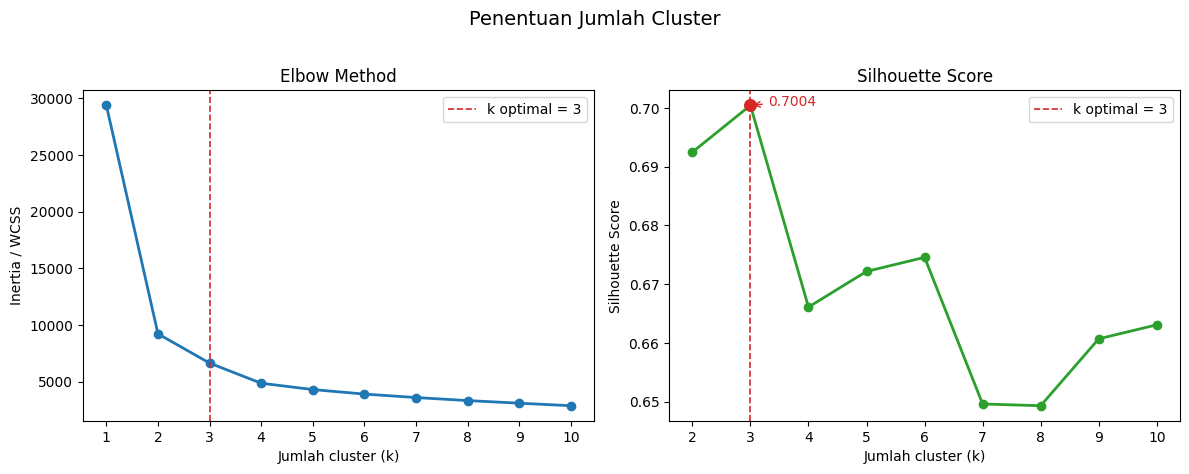

Grafik Elbow dan Silhouette berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_4_Elbow_Silhouette.png


In [ ]:
# ------------------------------------------------------------
# 5. ELBOW METHOD DAN SILHOUETTE SCORE (2.3.4)
# ------------------------------------------------------------

metrics = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(hasil_pca)
    row = {"k": k, "Inertia_WCSS": model.inertia_}
    row["Silhouette"] = silhouette_score(hasil_pca, labels) if k >= 2 else np.nan
    metrics.append(row)

metrics_df = pd.DataFrame(metrics)
display(metrics_df)

# Pilih k dengan nilai Silhouette tertinggi.
# Baris k=1 diabaikan karena Silhouette tidak dihitung untuk satu cluster.
skor_valid = metrics_df.dropna(subset=["Silhouette"])

if skor_valid.empty:
    raise ValueError("Tidak ada nilai Silhouette yang dapat digunakan.")

baris_terbaik = skor_valid.loc[skor_valid["Silhouette"].idxmax()]
k_optimal = int(baris_terbaik["k"])
silhouette_tertinggi = float(baris_terbaik["Silhouette"])

# Latih ulang K-Means menggunakan k terpilih
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
label_awal = kmeans.fit_predict(hasil_pca)

print("k terpilih berdasarkan Silhouette:", k_optimal)
print("Nilai Silhouette tertinggi:", silhouette_tertinggi)

# ------------------------------------------------------------
# GRAFIK 4. ELBOW METHOD DAN SILHOUETTE SCORE
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.6)
)

# ============================================================
# GRAFIK SEBELAH KIRI: ELBOW METHOD
# ============================================================

axes[0].plot(
    metrics_df["k"],
    metrics_df["Inertia_WCSS"],
    marker="o",
    color="#1f77b4",
    linewidth=2
)

# Menandai k optimal
axes[0].axvline(
    k_optimal,
    color="#d62728",
    linestyle="--",
    linewidth=1.2,
    label=f"k optimal = {k_optimal}"
)

axes[0].set_title(
    "Elbow Method"
)

axes[0].set_xlabel(
    "Jumlah cluster (k)"
)

axes[0].set_ylabel(
    "Inertia / WCSS"
)

axes[0].set_xticks(
    metrics_df["k"]
)

axes[0].legend()

# ============================================================
# GRAFIK SEBELAH KANAN: SILHOUETTE SCORE
# ============================================================

silhouette_data = metrics_df[
    metrics_df["k"] >= 2
]

axes[1].plot(
    silhouette_data["k"],
    silhouette_data["Silhouette"],
    marker="o",
    color="#2ca02c",
    linewidth=2
)

# Menandai k optimal
axes[1].axvline(
    k_optimal,
    color="#d62728",
    linestyle="--",
    linewidth=1.2,
    label=f"k optimal = {k_optimal}"
)

# Menandai nilai Silhouette tertinggi
axes[1].scatter(
    k_optimal,
    silhouette_tertinggi,
    color="#d62728",
    s=70,
    zorder=5
)

axes[1].annotate(
    f"{silhouette_tertinggi:.4f}",
    xy=(k_optimal, silhouette_tertinggi),
    xytext=(k_optimal + 0.3, silhouette_tertinggi),
    arrowprops=dict(
        arrowstyle="->",
        color="#d62728"
    ),
    color="#d62728"
)

axes[1].set_title(
    "Silhouette Score"
)

axes[1].set_xlabel(
    "Jumlah cluster (k)"
)

axes[1].set_ylabel(
    "Silhouette Score"
)

axes[1].set_xticks(
    range(2, 11)
)

axes[1].legend()

# Judul keseluruhan
fig.suptitle(
    "Penentuan Jumlah Cluster",
    fontsize=14,
    y=1.02
)

plt.tight_layout()

# Menyimpan grafik
nama_file_cluster = (
    f"{GRAFIK_DIR}/Gambar_4_Elbow_Silhouette.png"
)

plt.savefig(
    nama_file_cluster,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik langsung setelah tabel metrik
plt.show()

plt.close()

print(
    "Grafik Elbow dan Silhouette berhasil dibuat dan disimpan di:",
    nama_file_cluster
)


Pemetaan label asli K-Means ke nomor cluster berurutan:
Label asli 0 -> Cluster 1 (Sangat Puas)
Label asli 2 -> Cluster 2 (Puas)
Label asli 1 -> Cluster 3 (Kurang Puas)

Profil cluster:


,Cluster,Segmen,n,Persentase,Rata_Rata_Total,Affect of Service,Information Control,Library as Place
0,1,Sangat Puas,950,57.715674362089921,4.9296172248803831,4.9410526315789474,4.9161842105263158,4.9305263157894741
1,2,Puas,665,40.400972053462944,4.1016404647983595,4.1436925647451961,4.0486842105263161,4.1106766917293234
2,3,Kurang Puas,31,1.8833535844471445,2.9340175953079175,3.1648745519713262,2.6330645161290325,3


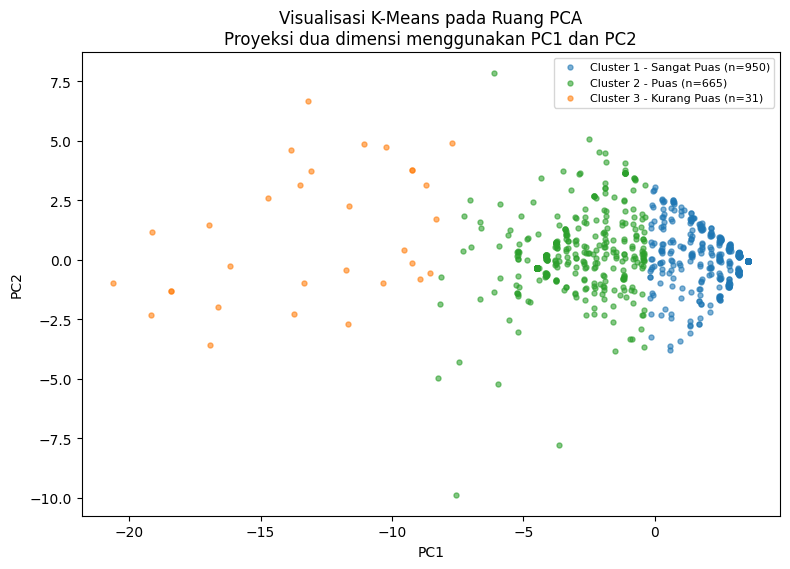

Scatter plot cluster berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_5_Scatter_Cluster_PCA.png


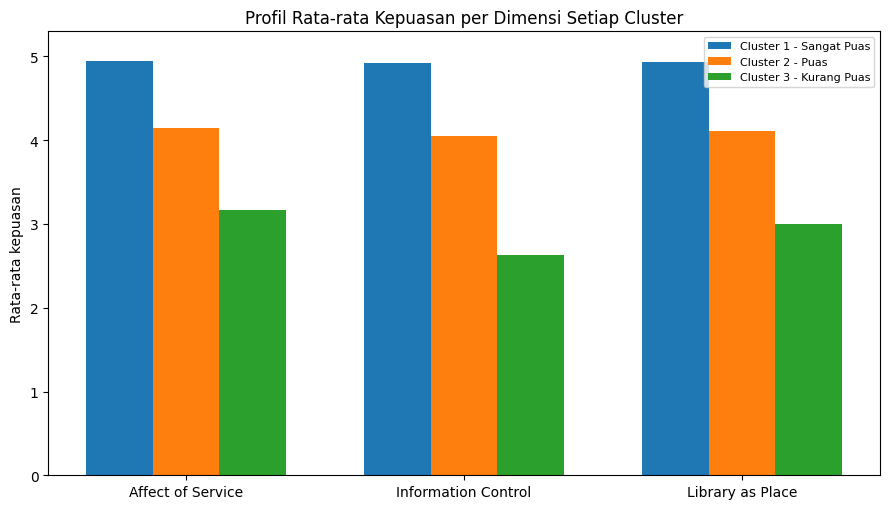

Grafik profil dimensi berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_6_Profil_Dimensi_Cluster.png


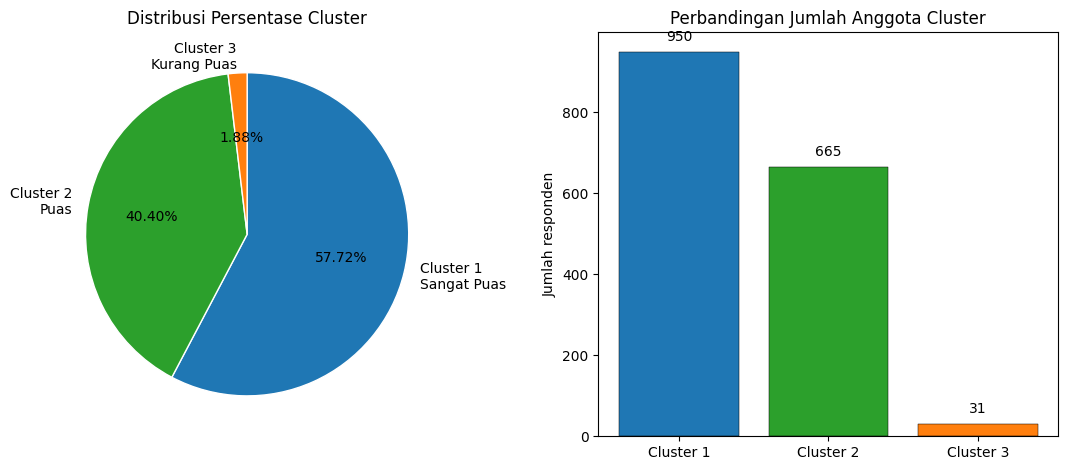

Grafik distribusi dan perbandingan cluster berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_7_Distribusi_Perbandingan_Cluster.png


In [ ]:
# ------------------------------------------------------------
# 6. PROFIL CLUSTER DAN PENGURUTAN LABEL (2.3.5-2.3.6)
# ------------------------------------------------------------

# Pastikan jumlah label hasil K-Means sama dengan jumlah data
if len(label_awal) != len(data_survei):
    raise ValueError(
        "Jumlah label cluster tidak sama dengan jumlah baris data survei."
    )

clustered = data_survei.copy()

# Hitung rata-rata kepuasan setiap respons
clustered["Total_Kepuasan"] = data_survei.mean(axis=1)

# Simpan label asli K-Means, yang biasanya dimulai dari 0
clustered["Cluster_raw"] = label_awal

# Pastikan jumlah cluster yang terbentuk sesuai dengan k terpilih
jumlah_cluster = clustered["Cluster_raw"].nunique()

if jumlah_cluster != k_optimal:
    raise ValueError(
        f"Jumlah cluster yang terbentuk ({jumlah_cluster}) "
        f"tidak sama dengan k terpilih ({k_optimal})."
    )

# Urutkan label berdasarkan rata-rata kepuasan,
# dari tertinggi ke terendah
rata_rata_cluster_asli = (
    clustered.groupby("Cluster_raw")["Total_Kepuasan"]
    .mean()
    .sort_values(ascending=False)
)

# Petakan label asli K-Means menjadi Cluster 1, 2, 3, dan seterusnya
label_map = {
    label_asli: nomor_cluster
    for nomor_cluster, label_asli in enumerate(
        rata_rata_cluster_asli.index,
        start=1
    )
}

clustered["Cluster"] = clustered["Cluster_raw"].map(label_map)

# Beri nama segmen jika jumlah cluster yang terpilih adalah 3.
# Jika jumlahnya berbeda, gunakan nama netral agar tidak salah memberi label.
if k_optimal == 3:
    nama_segmen = {
        1: "Sangat Puas",
        2: "Puas",
        3: "Kurang Puas",
    }
else:
    nama_segmen = {
        nomor_cluster: f"Segmen {nomor_cluster}"
        for nomor_cluster in range(1, k_optimal + 1)
    }

clustered["Segmen"] = clustered["Cluster"].map(nama_segmen)

# Tentukan butir untuk setiap dimensi LibQUAL+
dimensi = {
    "Affect of Service": list(range(0, 9)),
    "Information Control": list(range(9, 17)),
    "Library as Place": list(range(17, 22)),
}

# Ambil nama kolom berdasarkan posisi butir pada data_survei
kolom_dimensi = {
    nama_dimensi: data_survei.columns[posisi].tolist()
    for nama_dimensi, posisi in dimensi.items()
}

# Hitung profil masing-masing cluster
profil = []

for cluster_id in range(1, jumlah_cluster + 1):
    sub = clustered[clustered["Cluster"] == cluster_id]

    if sub.empty:
        raise ValueError(f"Cluster {cluster_id} tidak memiliki data.")

    row = {
        "Cluster": cluster_id,
        "Segmen": nama_segmen[cluster_id],
        "n": len(sub),
        "Persentase": len(sub) / len(clustered) * 100,
        "Rata_Rata_Total": sub["Total_Kepuasan"].mean(),
    }

    # Hitung rata-rata tiap dimensi dalam cluster
    for nama_dimensi, kolom_butir in kolom_dimensi.items():
        row[nama_dimensi] = (
            sub[kolom_butir]
            .to_numpy(dtype=float)
            .mean()
        )

    profil.append(row)

profil_df = pd.DataFrame(profil)

# Tampilkan pemetaan label asli K-Means ke nomor cluster berurutan
print("Pemetaan label asli K-Means ke nomor cluster berurutan:")
for label_asli, nomor_cluster in label_map.items():
    print(
        f"Label asli {label_asli} -> Cluster {nomor_cluster} "
        f"({nama_segmen[nomor_cluster]})"
    )

print("\nProfil cluster:")
with pd.option_context(
    "display.float_format",
    lambda nilai: format(nilai, ".17g")
):
    display(profil_df)

# ------------------------------------------------------------
# GRAFIK 5. SCATTER PLOT PADA RUANG PCA
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import pandas as pd
import os

# Pastikan folder grafik tersedia
GRAFIK_DIR = "grafik_7_gambar"
os.makedirs(GRAFIK_DIR, exist_ok=True)

# Membuat tabel skor PCA
pca_plot = pd.DataFrame(
    hasil_pca,
    columns=[
        f"PC{i + 1}"
        for i in range(hasil_pca.shape[1])
    ]
)

# Menambahkan label cluster
pca_plot["Cluster"] = clustered["Cluster"].to_numpy()

# Warna setiap cluster
warna = {
    1: "#1f77b4",   # Biru
    2: "#2ca02c",   # Hijau
    3: "#ff7f0e",   # Oranye
}

# Nama setiap segmen
nama_cluster = {
    1: "Cluster 1 - Sangat Puas",
    2: "Cluster 2 - Puas",
    3: "Cluster 3 - Kurang Puas",
}

# Membuat grafik
fig, ax = plt.subplots(figsize=(8, 5.8))

for cluster_id in sorted(
    pca_plot["Cluster"].unique()
):
    sub = pca_plot[
        pca_plot["Cluster"] == cluster_id
    ]

    ax.scatter(
        sub["PC1"],
        sub["PC2"],
        s=13,
        alpha=0.58,
        color=warna[cluster_id],
        label=(
            f"{nama_cluster[cluster_id]} "
            f"(n={len(sub)})"
        ),
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

ax.set_title(
    "Visualisasi K-Means pada Ruang PCA\n"
    "Proyeksi dua dimensi menggunakan PC1 dan PC2"
)

ax.legend(
    loc="best",
    fontsize=8
)

plt.tight_layout()

nama_file_scatter = (
    f"{GRAFIK_DIR}/Gambar_5_Scatter_Cluster_PCA.png"
)

plt.savefig(
    nama_file_scatter,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(
    "Scatter plot cluster berhasil dibuat dan disimpan di:",
    nama_file_scatter
)

# ------------------------------------------------------------
# GRAFIK 6. PROFIL RATA-RATA KEPUASAN
# SETIAP DIMENSI BERDASARKAN CLUSTER
# ------------------------------------------------------------

dimensi_grafik = [
    "Affect of Service",
    "Information Control",
    "Library as Place",
]

fig, ax = plt.subplots(
    figsize=(9, 5.2)
)

x = np.arange(
    len(dimensi_grafik)
)

jumlah_cluster_terpilih = len(
    profil_df["Cluster"].unique()
)

width = 0.24

for i, cluster_id in enumerate(
    sorted(profil_df["Cluster"].unique())
):
    baris_cluster = profil_df[
        profil_df["Cluster"] == cluster_id
    ].iloc[0]

    nilai_dimensi = [
        baris_cluster[nama_dimensi]
        for nama_dimensi in dimensi_grafik
    ]

    posisi_x = (
        x
        + (i - (jumlah_cluster_terpilih - 1) / 2)
        * width
    )

    ax.bar(
        posisi_x,
        nilai_dimensi,
        width,
        label=(
            f"Cluster {cluster_id} - "
            f"{baris_cluster['Segmen']}"
        ),
    )

ax.set_xticks(x)
ax.set_xticklabels(dimensi_grafik)

ax.set_ylim(0, 5.3)
ax.set_ylabel("Rata-rata kepuasan")

ax.set_title(
    "Profil Rata-rata Kepuasan "
    "per Dimensi Setiap Cluster"
)

ax.legend(fontsize=8)

plt.tight_layout()

nama_file_profil = (
    f"{GRAFIK_DIR}/Gambar_6_Profil_Dimensi_Cluster.png"
)

plt.savefig(
    nama_file_profil,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(
    "Grafik profil dimensi berhasil dibuat dan disimpan di:",
    nama_file_profil
)

# ------------------------------------------------------------
# GRAFIK 7. DISTRIBUSI DAN PERBANDINGAN CLUSTER
# ------------------------------------------------------------

# Mengambil nomor cluster
cluster_ids = sorted(
    profil_df["Cluster"].unique()
)

# Menggunakan warna yang sudah dibuat pada Gambar 5
warna_pie = [
    warna[cluster_id]
    for cluster_id in cluster_ids
]

# Membuat label pie chart
label_pie = []

for cluster_id in cluster_ids:
    nama_segmen_cluster = profil_df.loc[
        profil_df["Cluster"] == cluster_id,
        "Segmen"
    ].iloc[0]

    label_pie.append(
        f"Cluster {cluster_id}\n"
        f"{nama_segmen_cluster}"
    )

# Mengambil persentase setiap cluster
persentase_cluster = [
    profil_df.loc[
        profil_df["Cluster"] == cluster_id,
        "Persentase"
    ].iloc[0]
    for cluster_id in cluster_ids
]

# Mengambil jumlah anggota setiap cluster
jumlah_anggota = [
    profil_df.loc[
        profil_df["Cluster"] == cluster_id,
        "n"
    ].iloc[0]
    for cluster_id in cluster_ids
]

# Membuat dua grafik dalam satu gambar
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.8)
)

# ============================================================
# BAGIAN KIRI: PIE CHART
# ============================================================

axes[0].pie(
    persentase_cluster,
    labels=label_pie,
    colors=warna_pie,
    autopct="%.2f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={
        "edgecolor": "white"
    },
)

axes[0].set_title(
    "Distribusi Persentase Cluster"
)

# ============================================================
# BAGIAN KANAN: BAR CHART
# ============================================================

label_batang = [
    f"Cluster {cluster_id}"
    for cluster_id in cluster_ids
]

batang = axes[1].bar(
    label_batang,
    jumlah_anggota,
    color=warna_pie,
    edgecolor="black",
    linewidth=0.35,
)

axes[1].set_title(
    "Perbandingan Jumlah Anggota Cluster"
)

axes[1].set_ylabel(
    "Jumlah responden"
)

# Menampilkan jumlah di atas batang
for bar, jumlah in zip(
    batang,
    jumlah_anggota
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        jumlah + max(jumlah_anggota) * 0.02,
        f"{jumlah}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()

# Menyimpan grafik
nama_file_distribusi = (
    f"{GRAFIK_DIR}/"
    "Gambar_7_Distribusi_Perbandingan_Cluster.png"
)

plt.savefig(
    nama_file_distribusi,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik langsung
plt.show()

plt.close()

print(
    "Grafik distribusi dan perbandingan cluster "
    "berhasil dibuat dan disimpan di:",
    nama_file_distribusi
)



Statistik deskriptif:


,Dimensi,Min,Max,Mean,Std_Dev
0,Affect of Service,2,5,4.585460,0.565396
1,Information Control,2,5,4.522707,0.608490
2,Library as Place,2,5,4.562940,0.578601
3,Rata-rata Total,2,5,4.557522,0.585021


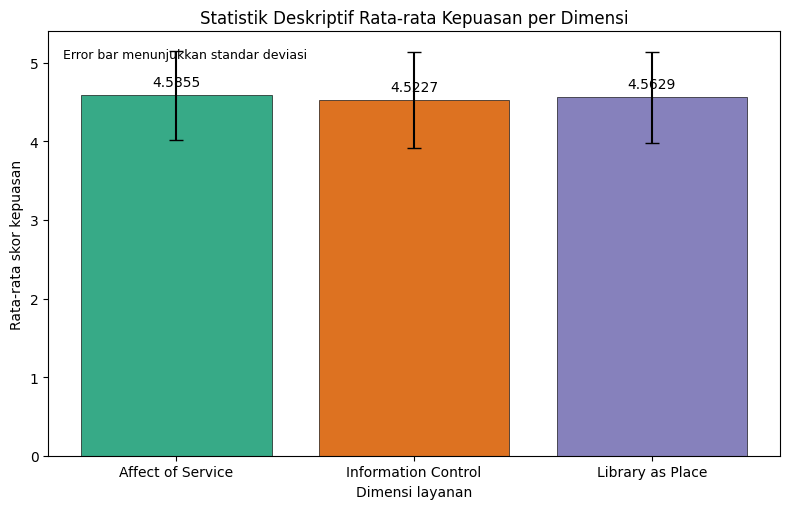

Grafik statistik deskriptif berhasil dibuat dan disimpan di: grafik_7_gambar/Gambar_8_Statistik_Deskriptif_Dimensi.png


In [ ]:
# ------------------------------------------------------------
# 7. STATISTIK DESKRIPTIF (3.1)
# ------------------------------------------------------------

deskriptif = []
for nama, indeks in dimensi.items():
    values = data_survei.iloc[:, indeks].to_numpy().ravel()
    deskriptif.append({
        "Dimensi": nama,
        "Min": values.min(),
        "Max": values.max(),
        "Mean": values.mean(),
        "Std_Dev": values.std(ddof=1),
    })

all_values = data_survei.to_numpy().ravel()
deskriptif.append({
    "Dimensi": "Rata-rata Total",
    "Min": all_values.min(),
    "Max": all_values.max(),
    "Mean": all_values.mean(),
    "Std_Dev": all_values.std(ddof=1),
})
deskriptif_df = pd.DataFrame(deskriptif)
print("Statistik deskriptif:")
display(deskriptif_df)

# ------------------------------------------------------------
# GRAFIK 8. STATISTIK DESKRIPTIF RATA-RATA PER DIMENSI
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import os

# Memastikan folder grafik tersedia
GRAFIK_DIR = "grafik_7_gambar"
os.makedirs(GRAFIK_DIR, exist_ok=True)

# Mengambil hanya tiga dimensi layanan
# Baris Rata-rata Total tidak dimasukkan ke grafik dimensi
deskriptif_dimensi = deskriptif_df[
    deskriptif_df["Dimensi"] != "Rata-rata Total"
].copy()

# Membuat posisi batang
x = np.arange(
    len(deskriptif_dimensi)
)

# Membuat grafik
fig, ax = plt.subplots(
    figsize=(8, 5.2)
)

batang = ax.bar(
    x,
    deskriptif_dimensi["Mean"],
    yerr=deskriptif_dimensi["Std_Dev"],
    capsize=5,
    color=[
        "#1b9e77",
        "#d95f02",
        "#7570b3",
    ],
    alpha=0.88,
    edgecolor="black",
    linewidth=0.5,
)

# Label sumbu horizontal
ax.set_xticks(x)
ax.set_xticklabels(
    deskriptif_dimensi["Dimensi"]
)

# Pengaturan sumbu dan judul
ax.set_ylim(0, 5.4)
ax.set_xlabel("Dimensi layanan")
ax.set_ylabel("Rata-rata skor kepuasan")
ax.set_title(
    "Statistik Deskriptif Rata-rata Kepuasan "
    "per Dimensi"
)

# Menampilkan nilai rata-rata di atas setiap batang
for bar, nilai in zip(
    batang,
    deskriptif_dimensi["Mean"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{nilai:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Keterangan error bar
ax.text(
    0.02,
    0.96,
    "Error bar menunjukkan standar deviasi",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
)

plt.tight_layout()

# Menyimpan grafik
nama_file_deskriptif = (
    f"{GRAFIK_DIR}/"
    "Gambar_8_Statistik_Deskriptif_Dimensi.png"
)

plt.savefig(
    nama_file_deskriptif,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik langsung di Colab
plt.show()

plt.close()

print(
    "Grafik statistik deskriptif berhasil dibuat "
    "dan disimpan di:",
    nama_file_deskriptif
)



ANOVA F: 6592.347708880623
ANOVA p-value: 0.0

Tukey HSD:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     1      2   -0.828   0.0 -0.8473 -0.8086   True
     1      3  -1.9956   0.0 -2.0655 -1.9257   True
     2      3  -1.1676   0.0  -1.238 -1.0973   True
---------------------------------------------------

Levene statistic: 89.68370471936977
Levene p-value: 1.0810197292427508e-37

Kruskal-Wallis H: 1307.0251976211046
Kruskal-Wallis p-value: 1.5243492531710398e-284


/tmp/ipykernel_709/741384968.py:68: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


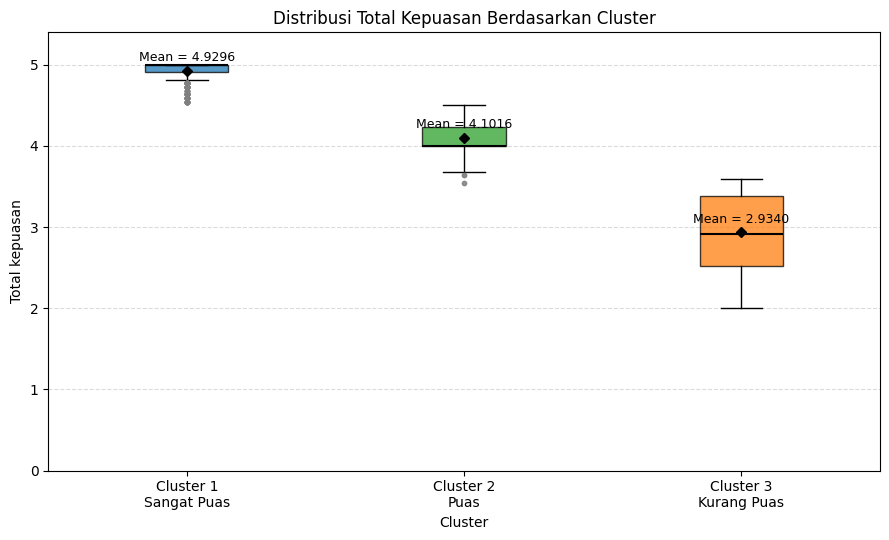

Grafik distribusi total kepuasan berhasil dibuat dan disimpan di: grafik_9_gambar/Gambar_9_Distribusi_Total_Kepuasan_Cluster.png


In [ ]:
# ------------------------------------------------------------
# 8. ANOVA, TUKEY HSD, LEVENE, KRUSKAL-WALLIS (2.3.6 dan 3.4 - 3.5)
# ------------------------------------------------------------

kelompok = [
    clustered.loc[clustered["Cluster"] == k, "Total_Kepuasan"]
    for k in [1, 2, 3]
]

F_stat, anova_p_value = f_oneway(*kelompok)
levene_stat, levene_p_value = levene(*kelompok, center="median")
kruskal_stat, kruskal_p_value = kruskal(*kelompok)
tukey = pairwise_tukeyhsd(
    endog=clustered["Total_Kepuasan"],
    groups=clustered["Cluster"],
    alpha=0.05,
)

print("\nANOVA F:", F_stat)
print("ANOVA p-value:", anova_p_value)
print("\nTukey HSD:")
print(tukey)
print("\nLevene statistic:", levene_stat)
print("Levene p-value:", levene_p_value)
print("\nKruskal-Wallis H:", kruskal_stat)
print("Kruskal-Wallis p-value:", kruskal_p_value)

# ------------------------------------------------------------
# GRAFIK 9. DISTRIBUSI TOTAL KEPUASAN BERDASARKAN CLUSTER
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import os

# Pastikan folder grafik tersedia
GRAFIK_DIR = "grafik_9_gambar"
os.makedirs(GRAFIK_DIR, exist_ok=True)

# Cluster yang tersedia
cluster_ids = sorted(
    clustered["Cluster"].unique()
)

# Mengambil data total kepuasan setiap cluster
data_boxplot = [
    clustered.loc[
        clustered["Cluster"] == cluster_id,
        "Total_Kepuasan"
    ].to_numpy()
    for cluster_id in cluster_ids
]

# Membuat label cluster
label_cluster = [
    (
        f"Cluster {cluster_id}\n"
        f"{nama_segmen[cluster_id]}"
    )
    for cluster_id in cluster_ids
]

# Membuat grafik
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

box = ax.boxplot(
    data_boxplot,
    labels=label_cluster,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 5,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 1,
    },
    capprops={
        "color": "black",
        "linewidth": 1,
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "gray",
        "markeredgecolor": "gray",
        "markersize": 3,
        "alpha": 0.45,
    },
)

# Warna box sesuai cluster
warna_box = [
    "#1f77b4",
    "#2ca02c",
    "#ff7f0e",
]

for patch, warna_cluster in zip(
    box["boxes"],
    warna_box
):
    patch.set_facecolor(warna_cluster)
    patch.set_alpha(0.75)

# Menambahkan nilai rata-rata pada grafik
for posisi, cluster_id in enumerate(
    cluster_ids,
    start=1
):
    nilai_rata_rata = clustered.loc[
        clustered["Cluster"] == cluster_id,
        "Total_Kepuasan"
    ].mean()

    ax.text(
        posisi,
        nilai_rata_rata + 0.08,
        f"Mean = {nilai_rata_rata:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Pengaturan sumbu dan judul
ax.set_ylim(0, 5.4)
ax.set_xlabel("Cluster")
ax.set_ylabel("Total kepuasan")
ax.set_title(
    "Distribusi Total Kepuasan Berdasarkan Cluster"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.45
)

plt.tight_layout()

# Menyimpan grafik
nama_file_anova = (
    f"{GRAFIK_DIR}/"
    "Gambar_9_Distribusi_Total_Kepuasan_Cluster.png"
)

plt.savefig(
    nama_file_anova,
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik langsung setelah hasil uji statistik
plt.show()

plt.close()

print(
    "Grafik distribusi total kepuasan berhasil dibuat "
    "dan disimpan di:",
    nama_file_anova
)


In [ ]:
# ------------------------------------------------------------
# 9. MENYIMPAN DAN MENGUNDUH SELURUH HASIL
# ------------------------------------------------------------

import os
import json
import zipfile
import shutil
import numpy as np
import pandas as pd
from google.colab import files

# Folder sementara di Google Colab
OUT = "/content/hasil_analisis_colab_final"
ZIP_PATH = "/content/hasil_analisis_colab_final.zip"

os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------
# Menyimpan file hasil analisis
# ------------------------------------------------------------

pd.DataFrame(hasil_pca, columns=kolom_pc).assign(
    Cluster=clustered["Cluster"].to_numpy(),
    Segmen=clustered["Segmen"].to_numpy(),
).to_excel(
    os.path.join(OUT, "Hasil_PCA_KMeans.xlsx"),
    index=False
)

data_survei.to_excel(
    os.path.join(OUT, "Data_Konversi_Likert.xlsx"),
    index=False
)

loadings.to_excel(
    os.path.join(OUT, "Factor_Loadings_Corrected.xlsx")
)

metrics_df.to_excel(
    os.path.join(OUT, "Cluster_Metrics_k1_k10.xlsx"),
    index=False
)

deskriptif_df.to_excel(
    os.path.join(OUT, "Statistik_Deskriptif.xlsx"),
    index=False
)

profil_df.to_excel(
    os.path.join(OUT, "Profil_Dimensi_Cluster.xlsx"),
    index=False
)

# Menyimpan hasil Tukey HSD
with open(
    os.path.join(OUT, "Tukey_HSD.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(str(tukey))

# ------------------------------------------------------------
# Menyalin semua grafik ke folder hasil
# ------------------------------------------------------------

for folder_grafik in [
    "/content/grafik_7_gambar",
    "/content/grafik_9_gambar"
]:
    if os.path.isdir(folder_grafik):
        nama_folder = os.path.basename(folder_grafik)
        folder_tujuan = os.path.join(OUT, nama_folder)

        os.makedirs(folder_tujuan, exist_ok=True)

        for nama_file in os.listdir(folder_grafik):
            sumber = os.path.join(folder_grafik, nama_file)
            tujuan = os.path.join(folder_tujuan, nama_file)

            if os.path.isfile(sumber):
                shutil.copy2(sumber, tujuan)

# ------------------------------------------------------------
# Menyimpan ringkasan analisis dalam format JSON
# ------------------------------------------------------------

def json_converter(obj):
    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, pd.Timestamp):
        return obj.isoformat()

    raise TypeError(
        f"Tipe data tidak dapat disimpan ke JSON: {type(obj)}"
    )

ringkasan = {
    "n_awal": int(len(data)),
    "missing_cells": int(missing_cells),
    "n_analisis": int(len(data_survei)),
    "kmo": float(kmo_model),
    "bartlett_chi_square": float(bartlett_chi2),
    "bartlett_p_value": float(bartlett_p_value),
    "cronbach_alpha": float(cronbach_alpha),
    "jumlah_komponen": int(jumlah_komponen),
    "varians_kumulatif": float(
        pca.explained_variance_ratio_.sum()
    ),
    "k_optimal": int(k_optimal),
    "silhouette_k3": float(
        metrics_df.loc[
            metrics_df["k"] == 3,
            "Silhouette"
        ].iloc[0]
    ),
    "anova_F": float(F_stat),
    "anova_p_value": float(anova_p_value),
    "levene_statistic": float(levene_stat),
    "levene_p_value": float(levene_p_value),
    "kruskal_H": float(kruskal_stat),
    "kruskal_p_value": float(kruskal_p_value),
    "tukey_hsd": str(tukey),
    "profil_cluster": profil_df.to_dict(
        orient="records"
    ),
}

with open(
    os.path.join(OUT, "summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        ringkasan,
        f,
        ensure_ascii=False,
        indent=2,
        default=json_converter
    )

# ------------------------------------------------------------
# Membuat file ZIP
# ------------------------------------------------------------

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for root, folders, filenames in os.walk(OUT):
        for filename in filenames:
            filepath = os.path.join(root, filename)

            # Isi ZIP akan berada dalam folder utama
            arcname = os.path.relpath(
                filepath,
                "/content"
            )

            z.write(filepath, arcname=arcname)

print("\nAnalisis selesai.")
print(f"File ZIP siap diunduh: {ZIP_PATH}")

# Mengunduh file ZIP langsung ke komputer
files.download(ZIP_PATH)



Analisis selesai.
File ZIP siap diunduh: /content/hasil_analisis_colab_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>